<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Gradient_Boosting/adult_income_gradient_boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradient Boosting Project: Predict Who Earns More Than $50K

**Goal:** from a person's census record (age, education, job, hours worked, and so on), predict whether they earn **more than $50,000 a year**.

**What is gradient boosting?** Instead of one big model, you build **many small decision trees, one after another**. Each new tree is trained to fix the **mistakes** the previous trees still make, and a small **learning rate** keeps every step cautious. Add up all the little corrections and you get one very strong model. This family (XGBoost, LightGBM, CatBoost, scikit-learn's `HistGradientBoosting`) is the go-to choice for **table-style data** and wins a large share of real-world competitions.

**Compare with Random Forest:** a forest grows many trees **independently** and averages them. Boosting grows them **in sequence**, each one correcting the last.

**What you will learn**

- How boosting works, by building a tiny version **from scratch** and watching it improve round by round.
- How to handle **categorical columns and missing values** in a real data set.
- The key settings: `learning_rate`, number of rounds, tree size, regularization, and **early stopping**.
- How to tune with a random search, and how to **explain** the model with permutation importance and partial dependence plots.
- A look at whether the model works equally well for different groups of people.

**Dataset:** the Adult Census Income data (about 32,500 people, 14 columns), a classic from the UCI Machine Learning Repository. It is loaded from a URL below, so nothing needs to be uploaded.

**Steps:** 1) Load, 2) Explore, 3) Prepare, 4) Baselines, 5) Boosting from scratch, 6) Gradient boosting on the real data, 7) Learning rate and early stopping, 8) Tune, 9) Final test, 10) Explain the model, 11) Are the probabilities trustworthy?, 12) Different groups, 13) Optional: XGBoost, 14) Predict a person.

Run the cells from top to bottom (Shift + Enter).

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://huggingface.co/datasets/scikit-learn/adult-census-income/raw/main/adult.csv'
df = pd.read_csv(url, na_values='?')   # in this file, missing values are written as a question mark

print('Rows and columns:', df.shape)
df.head()

Rows and columns: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


*If this link ever stops working, search for "Adult Census Income" on Kaggle or the UCI repository, download the CSV, upload it to Colab and use `pd.read_csv('adult.csv', na_values='?')`.*

Each row is one person. The last column, `income`, is what we want to predict (`<=50K` or `>50K`).

## Step 2: Explore the data

In [2]:
df.info()
print()
print('Missing values per column (only columns with missing values):')
missing = df.isna().sum()
print(missing[missing > 0].to_string())
print()
print('Fully duplicated rows:', int(df.duplicated().sum()))
print()
print('Income groups:')
print(df['income'].value_counts().to_string())
print('Share earning more than 50K: {:.1%}'.format((df['income'] == '>50K').mean()))
df.describe().T.round(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Missing values per column (only columns with missing values):
workclass         1836
occupat

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.6,13.6,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.4,105550.0,12285.0,117827.0,178356.0,237051.0,1484705.0
education.num,32561.0,10.1,2.6,1.0,9.0,10.0,12.0,16.0
capital.gain,32561.0,1077.6,7385.3,0.0,0.0,0.0,0.0,99999.0
capital.loss,32561.0,87.3,403.0,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32561.0,40.4,12.3,1.0,40.0,40.0,45.0,99.0


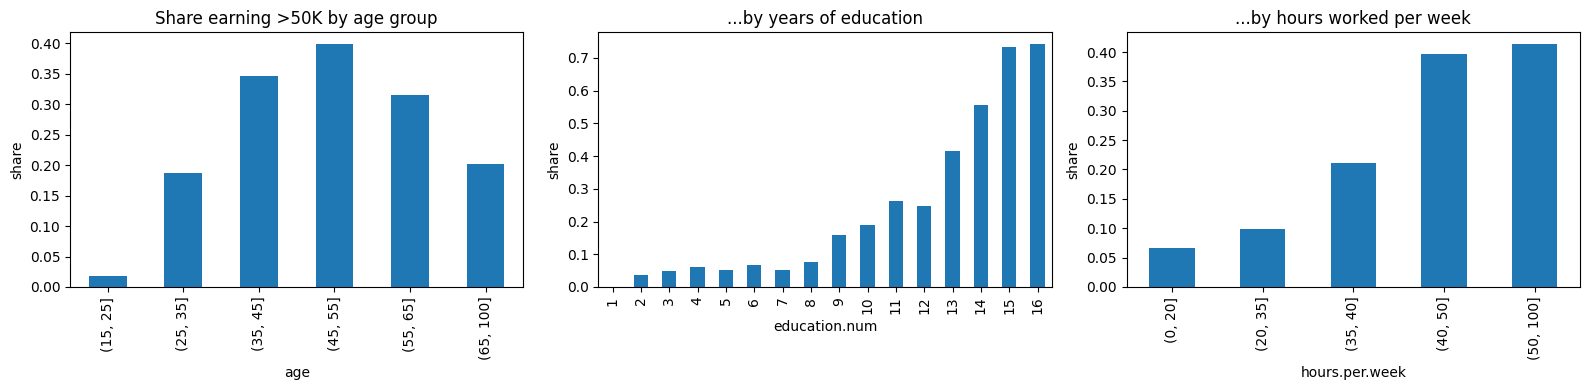

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
d = df.assign(rich=(df['income'] == '>50K'))
d.groupby(pd.cut(d['age'], [15, 25, 35, 45, 55, 65, 100]), observed=True)['rich'].mean().plot.bar(ax=axes[0])
axes[0].set_title('Share earning >50K by age group')
d.groupby('education.num')['rich'].mean().plot.bar(ax=axes[1])
axes[1].set_title('...by years of education')
d.groupby(pd.cut(d['hours.per.week'], [0, 20, 35, 40, 50, 100]), observed=True)['rich'].mean().plot.bar(ax=axes[2])
axes[2].set_title('...by hours worked per week')
for a in axes:
    a.set_ylabel('share')
plt.tight_layout()
plt.show()

**What to notice:**
- Only about one person in four earns more than $50K, so the classes are **imbalanced** and plain accuracy is flattered by the majority ("<=50K") answer.
- A few columns (`workclass`, `occupation`, `native.country`) have missing values. Gradient boosting trees can handle missing values **natively**, so we do not need to invent a replacement.
- Income rises with age (up to middle age), with education and with hours worked, so there is plenty of signal.

## Step 3: Prepare the data

- We turn `income` into a 0/1 target (`1` means more than $50K).
- We drop `fnlwgt` (a sampling weight from the census, not a property of the person) and `education` (it is the same information as `education.num`, just written as words).
- The text columns are **categorical**. We convert them to integer codes with an `OrdinalEncoder`, and tell the model which columns are categorical so it treats the codes as **labels, not as an order**. Missing values stay missing.
- We split off 25% as a **test set**, stratified so both parts have the same share of high earners.

The encoder is part of a **pipeline**, so it only learns from the training data.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer

df = df.drop_duplicates().reset_index(drop=True)
y = (df['income'] == '>50K').astype(int)
X = df.drop(columns=['income', 'fnlwgt', 'education'])

cat_cols = ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
num_cols = [c for c in X.columns if c not in cat_cols]
X = X.astype({c: float for c in num_cols})   # floats (not integers) keep the partial dependence plots happy later
print('Categorical columns:', cat_cols)
print('Numeric columns    :', num_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print()
print('Training people:', len(X_train), '| Test people:', len(X_test))
print('High earners in training: {:.1%} | in test: {:.1%}'.format(y_train.mean(), y_test.mean()))


def ordinal_prep():
    # categories -> integer codes; unseen or missing categories -> NaN (the model handles NaN itself)
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan, encoded_missing_value=np.nan)
    return ColumnTransformer([('cat', enc, cat_cols)], remainder='passthrough', verbose_feature_names_out=False)


# after the transformer the columns are: the categorical ones first, then the numeric ones
cat_mask = [True] * len(cat_cols) + [False] * len(num_cols)

Categorical columns: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Numeric columns    : ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

Training people: 24402 | Test people: 8135
High earners in training: 24.1% | in test: 24.1%


## Step 4: Baselines

Before using a powerful model, we measure simpler ones. We use **5-fold cross-validation on the training set** and look at accuracy and **ROC-AUC** (the chance that a random high earner gets a higher score than a random lower earner).

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = make_pipeline(
    ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
                       ('num', StandardScaler(), num_cols)]),
    LogisticRegression(max_iter=2000),
)
forest = make_pipeline(
    ordinal_prep(),
    SimpleImputer(strategy='constant', fill_value=-1),
    RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=42),
)
baselines = {
    'Baseline (always "<=50K")': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': logreg,
    'Random forest': forest,
}

rows = []
for name, m in baselines.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    rows.append({'model': name, 'accuracy': r['test_accuracy'].mean(), 'roc_auc': r['test_roc_auc'].mean()})
cv_table = pd.DataFrame(rows)
print(cv_table.round(3).to_string(index=False))

                    model  accuracy  roc_auc
Baseline (always "<=50K")     0.759    0.500
      Logistic regression     0.852    0.908
            Random forest     0.865    0.919


**What to notice:** the "always <=50K" baseline already has a high accuracy (it is right about three times out of four) but a ROC-AUC of 0.5, which is pure guessing. Use ROC-AUC to see real skill. Logistic regression and the random forest give us numbers to beat.

## Step 5: Boosting from scratch

Before we use the library, let us build the idea in about 15 lines. We create a wavy curve with noise, then repeat:

1. Start with a flat prediction (the average).
2. Compute the **residuals** (the mistakes: actual minus predicted).
3. Fit a **small tree** to the residuals.
4. Add a **small fraction** of that tree (the **learning rate**) to the prediction.
5. Go back to step 2.

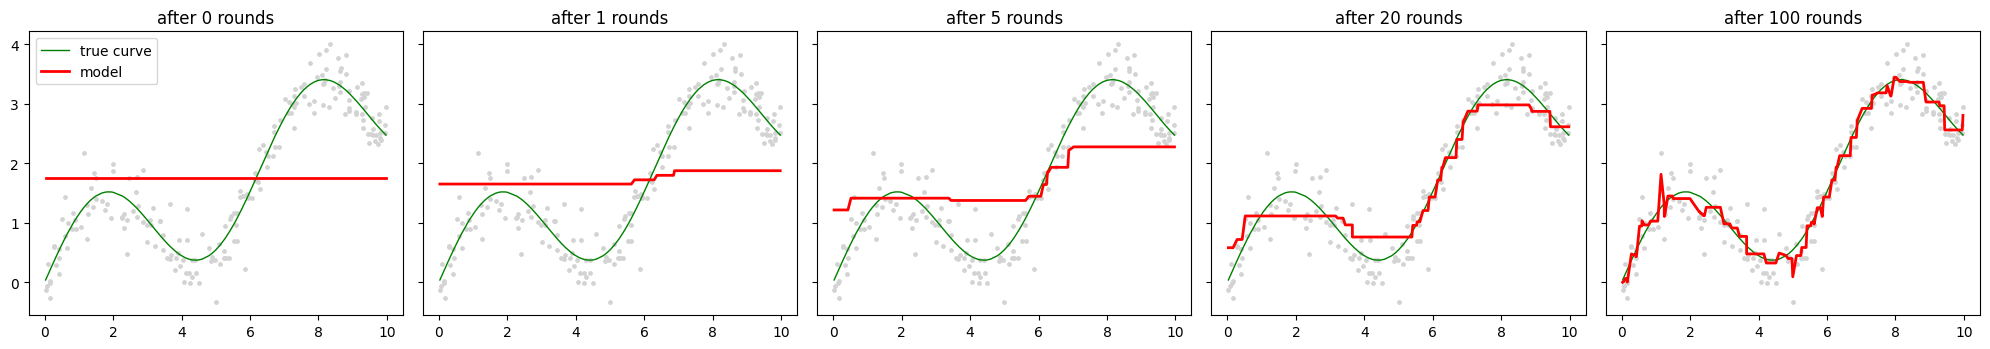

after   0 rounds: error against the true curve (RMSE) = 1.084
after   1 rounds: error against the true curve (RMSE) = 0.986
after   5 rounds: error against the true curve (RMSE) = 0.687
after  20 rounds: error against the true curve (RMSE) = 0.252
after 100 rounds: error against the true curve (RMSE) = 0.126


In [6]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 10, 200))
true_curve = np.sin(x) + 0.3 * x
y_toy = true_curve + rng.normal(0, 0.3, x.size)
Xt = x.reshape(-1, 1)

learning_rate = 0.1
pred = np.full_like(y_toy, y_toy.mean())          # step 1: start with the average
snapshots = {0: pred.copy()}
for round_no in range(1, 101):
    residual = y_toy - pred                         # step 2: the mistakes
    tree = DecisionTreeRegressor(max_depth=2).fit(Xt, residual)   # step 3: a small tree on the mistakes
    pred = pred + learning_rate * tree.predict(Xt)  # step 4: add a small fraction
    if round_no in (1, 5, 20, 100):
        snapshots[round_no] = pred.copy()

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
for ax, (r, p) in zip(axes, snapshots.items()):
    ax.scatter(x, y_toy, s=6, color='lightgray')
    ax.plot(x, true_curve, color='green', linewidth=1, label='true curve')
    ax.plot(x, p, color='red', linewidth=2, label='model')
    ax.set_title(f'after {r} rounds')
axes[0].legend()
plt.tight_layout()
plt.show()

for r, p in snapshots.items():
    print(f'after {r:>3} rounds: error against the true curve (RMSE) = {np.sqrt(np.mean((p - true_curve) ** 2)):.3f}')

**What to notice:** the red line starts flat and **gradually bends toward the true curve** as small trees fix the leftover mistakes. Each tree alone is weak (a depth-2 tree), but 100 of them make a good fit. If you keep adding rounds forever, the line eventually starts chasing the **noise** (overfitting), which is why we need early stopping later.

In real gradient boosting for classification, the "mistakes" are measured by the gradient of the log-loss, which is where the name comes from. The idea is the same.

## Step 6: Gradient boosting on the real data

scikit-learn has a fast, modern implementation called `HistGradientBoostingClassifier` (similar to LightGBM). It handles missing values and categorical columns directly. We train it with default settings and compare with the baselines.

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier


def make_hgb(**params):
    return make_pipeline(ordinal_prep(),
                         HistGradientBoostingClassifier(categorical_features=cat_mask, random_state=42, **params))


hgb_default = make_hgb()
r = cross_validate(hgb_default, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
cv_table = pd.concat([cv_table, pd.DataFrame([{'model': 'Gradient boosting (default)',
                                               'accuracy': r['test_accuracy'].mean(),
                                               'roc_auc': r['test_roc_auc'].mean()}])], ignore_index=True)
print(cv_table.round(3).to_string(index=False))

                      model  accuracy  roc_auc
  Baseline (always "<=50K")     0.759    0.500
        Logistic regression     0.852    0.908
              Random forest     0.865    0.919
Gradient boosting (default)     0.873    0.929


**What to notice:** with no tuning at all, gradient boosting is usually at or near the top of this table. That "strong out of the box" property is a big part of why people love it for table data.

## Step 7: Learning rate, number of rounds and early stopping

The two most important settings are linked:

- `learning_rate`: how big each correction step is. **Smaller steps** are safer but need **more rounds**.
- `max_iter`: the maximum number of rounds (trees).

Too many rounds overfit. **Early stopping** solves it: the model keeps a validation slice aside and **stops adding trees when the validation score stops improving**. Below we train with three learning rates and plot the validation loss after each round (lower is better).

learning_rate=0.3   -> stopped after 58 rounds, best validation loss 0.2725
learning_rate=0.1   -> stopped after 119 rounds, best validation loss 0.2698
learning_rate=0.03  -> stopped after 329 rounds, best validation loss 0.2707


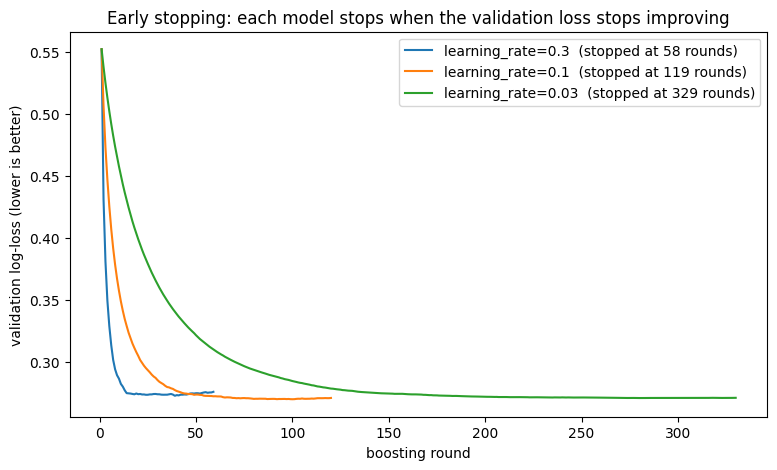

In [8]:
plt.figure(figsize=(9, 5))
for lr in [0.3, 0.1, 0.03]:
    prep = ordinal_prep()
    Xp = prep.fit_transform(X_train)
    m = HistGradientBoostingClassifier(categorical_features=cat_mask, learning_rate=lr, max_iter=1000,
                                       early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
                                       scoring='loss', random_state=42).fit(Xp, y_train)
    val_loss = -np.array(m.validation_score_)
    plt.plot(range(1, len(val_loss) + 1), val_loss, label=f'learning_rate={lr}  (stopped at {m.n_iter_} rounds)')
    print(f'learning_rate={lr:<5} -> stopped after {m.n_iter_} rounds, best validation loss {val_loss.min():.4f}')

plt.xlabel('boosting round')
plt.ylabel('validation log-loss (lower is better)')
plt.title('Early stopping: each model stops when the validation loss stops improving')
plt.legend()
plt.show()

**How to read the plot:** every curve falls, flattens and then stops. A **large learning rate** learns fast but may bottom out at a slightly worse loss; a **small learning rate** needs many more rounds and often (not always) ends a bit better. A common recipe is to pick a small learning rate and let early stopping choose the number of rounds.

## Step 8: Tune the other settings

We now search over the settings that control the **size of each tree** and how much we **regularize**:

- `max_leaf_nodes` and `max_depth`: how complex each tree may be (small trees = more careful model).
- `min_samples_leaf`: the minimum number of people in a leaf.
- `l2_regularization`: a penalty that shrinks the leaf values.
- `learning_rate`: the step size.

We use `RandomizedSearchCV` (tries random combinations; faster than testing every one), scoring by ROC-AUC, with early stopping so the number of rounds takes care of itself.

In [9]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_dist = {
    'histgradientboostingclassifier__learning_rate': loguniform(0.02, 0.3),
    'histgradientboostingclassifier__max_leaf_nodes': [8, 15, 31, 63],
    'histgradientboostingclassifier__max_depth': [None, 4, 6, 8],
    'histgradientboostingclassifier__min_samples_leaf': [10, 20, 40, 80],
    'histgradientboostingclassifier__l2_regularization': loguniform(1e-3, 10),
}
search = RandomizedSearchCV(
    make_hgb(max_iter=500, early_stopping=True, validation_fraction=0.15, n_iter_no_change=20),
    param_dist, n_iter=20, cv=3, scoring='roc_auc', n_jobs=-1, random_state=42,
)
search.fit(X_train, y_train)

print('Best cross-validated ROC-AUC:', round(search.best_score_, 4))
print('Best settings:')
for k, v in search.best_params_.items():
    print('   ', k.replace('histgradientboostingclassifier__', ''), '=', round(v, 4) if isinstance(v, float) else v)
print('Rounds used by the best model:', search.best_estimator_[-1].n_iter_)

best_gb = search.best_estimator_

Best cross-validated ROC-AUC: 0.9291
Best settings:
    l2_regularization = 0.2342
    learning_rate = 0.0227
    max_depth = 6
    max_leaf_nodes = 31
    min_samples_leaf = 10
Rounds used by the best model: 500


**What to notice:** the tuned score is usually only a little better than the default, because gradient boosting defaults are already good. Tuning mostly buys small, steady gains. If you have more time, try more iterations (`n_iter`) or wider ranges.

## Step 9: Final evaluation on the test set

This is the first time the **test set** is used. We fit the tuned model and compare it with the baselines on **the same test people**.

                      model  accuracy  roc_auc
  Baseline (always "<=50K")     0.759    0.500
        Logistic regression     0.850    0.901
              Random forest     0.862    0.912
Gradient boosting (default)     0.871    0.921
  Gradient boosting (tuned)     0.872    0.921

              precision    recall  f1-score   support

       <=50K      0.897     0.940     0.918      6175
        >50K      0.777     0.660     0.713      1960

    accuracy                          0.872      8135
   macro avg      0.837     0.800     0.816      8135
weighted avg      0.868     0.872     0.869      8135



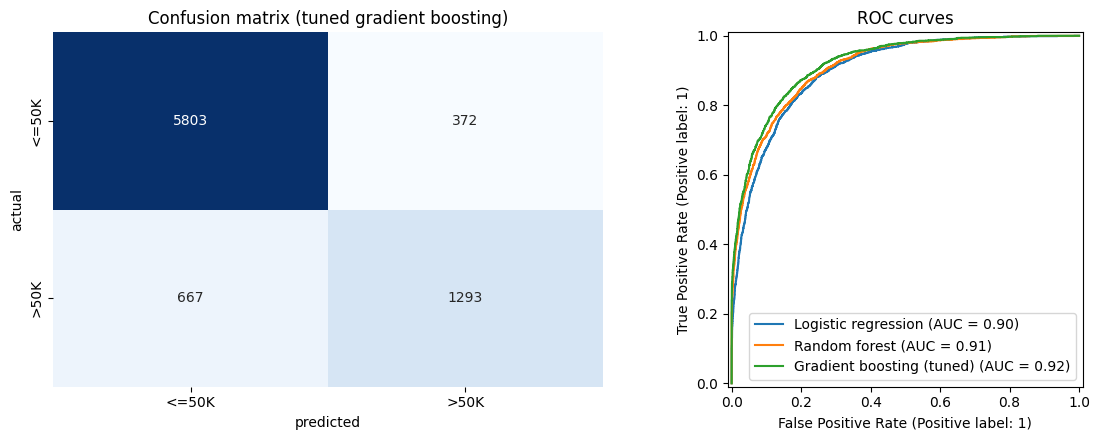

In [10]:
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report, confusion_matrix,
                             RocCurveDisplay)
import warnings

all_models = {
    'Baseline (always "<=50K")': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': logreg,
    'Random forest': forest,
    'Gradient boosting (default)': hgb_default,
    'Gradient boosting (tuned)': best_gb,
}

rows = []
test_proba = {}
for name, m in all_models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    test_proba[name] = p
    rows.append({'model': name, 'accuracy': accuracy_score(y_test, m.predict(X_test)),
                 'roc_auc': roc_auc_score(y_test, p)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

pred = best_gb.predict(X_test)
print()
print(classification_report(y_test, pred, target_names=['<=50K', '>50K'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('actual')
axes[0].set_title('Confusion matrix (tuned gradient boosting)')
for name in ['Logistic regression', 'Random forest', 'Gradient boosting (tuned)']:
    RocCurveDisplay.from_predictions(y_test, test_proba[name], name=name, ax=axes[1])
axes[1].set_title('ROC curves')
plt.tight_layout()
plt.show()

**How to read this:**
- Compare the **ROC-AUC** column. The boosted model is usually the best or close to the best, and the lazy baseline sits at 0.5.
- In the classification report, notice that **recall for ">50K"** is clearly lower than for "<=50K": the rare class is harder to catch at the default 0.5 cut-off. If finding high earners matters more than avoiding false alarms, lower the threshold (see the practice ideas).
- Differences of a few thousandths between the top models are within the noise. Do not over-interpret them.

## Step 10: Explain the model

A boosted model has hundreds of trees, so we cannot read it like a single tree. Two tools help to open the black box:

- **Permutation importance:** shuffle one column in the test data and measure **how much the ROC-AUC drops**. A big drop means the model relied on that column.
- **Partial dependence plots:** show how the predicted chance of ">50K" changes as one feature changes, with the others averaged out.

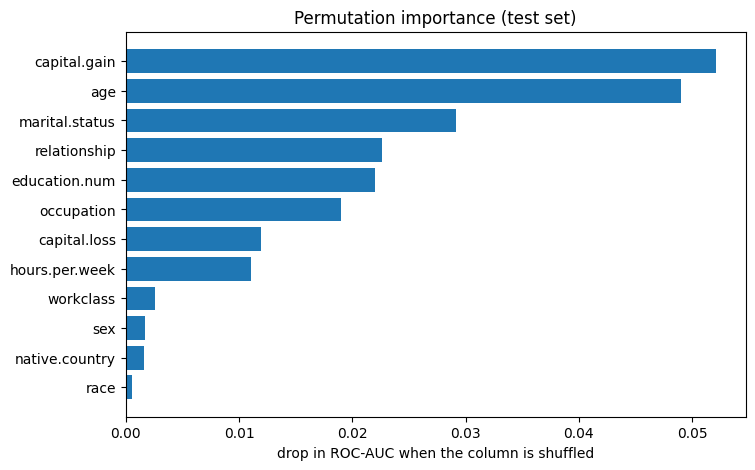

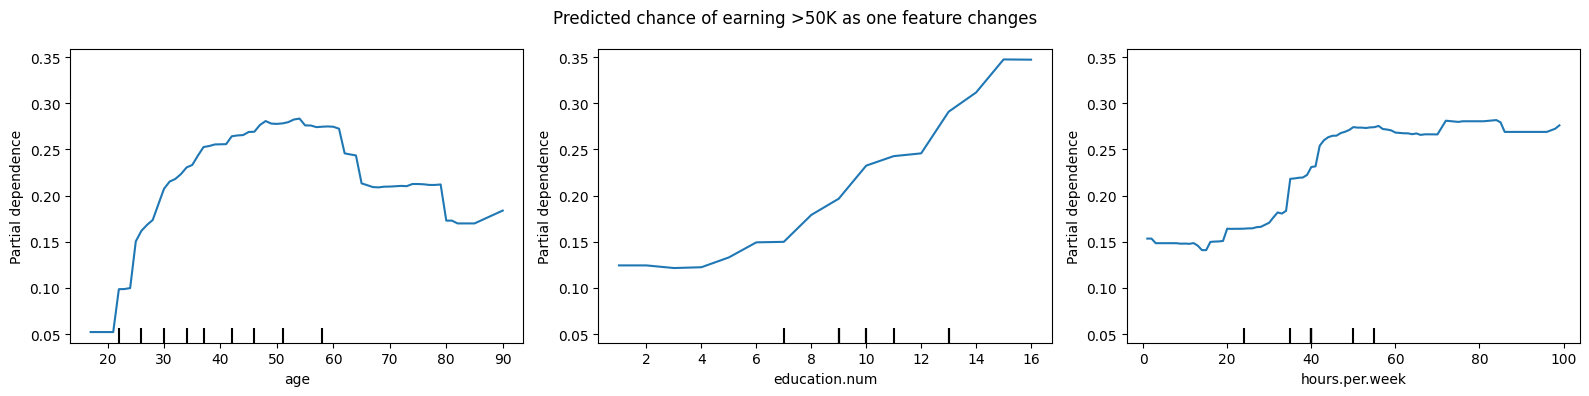

In [11]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

imp = permutation_importance(best_gb, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({'feature': X_test.columns, 'drop in ROC-AUC': imp.importances_mean}).sort_values('drop in ROC-AUC')

plt.figure(figsize=(8, 5))
plt.barh(imp_df['feature'], imp_df['drop in ROC-AUC'])
plt.xlabel('drop in ROC-AUC when the column is shuffled')
plt.title('Permutation importance (test set)')
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
PartialDependenceDisplay.from_estimator(best_gb, X_test, ['age', 'education.num', 'hours.per.week'], ax=ax)
fig.suptitle('Predicted chance of earning >50K as one feature changes')
plt.tight_layout()
plt.show()

**What to notice:** look at which columns sit at the top of the importance chart (typically things like marital status or relationship, education, age, capital gains and hours worked). The partial dependence plots show the **shape** of each relationship: for example, the chance rises with years of education and with age up to middle age, then flattens or falls. Importance tells you **what matters**; partial dependence tells you **how**. Neither proves that something *causes* higher income.

## Step 11: Are the predicted probabilities trustworthy?

The model outputs a **probability** for each person. If it says "70%", do about 70 out of 100 such people really earn more than $50K? We group the test people by predicted probability and compare with what actually happened.

In [12]:
proba = test_proba['Gradient boosting (tuned)']
bins = pd.cut(proba, [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], include_lowest=True)
calib = (pd.DataFrame({'bin': bins, 'actual': y_test.values, 'predicted': proba})
         .groupby('bin', observed=True)
         .agg(people=('actual', 'size'), actual_share=('actual', 'mean'), average_prediction=('predicted', 'mean')))
print(calib.round(3).to_string())

               people  actual_share  average_prediction
bin                                                    
(-0.001, 0.1]    4310         0.025               0.020
(0.1, 0.3]       1330         0.189               0.186
(0.3, 0.5]        830         0.369               0.392
(0.5, 0.7]        640         0.594               0.595
(0.7, 0.9]        517         0.791               0.782
(0.9, 1.0]        508         0.992               0.983


**How to read this:** in each row, `average_prediction` should be close to `actual_share`. Gradient boosting trained with log-loss is usually reasonably well calibrated, unlike Naive Bayes, but always check before using the probabilities for decisions.

## Step 12: Does the model work equally well for different groups?

A model can have a good overall score and still work worse for some groups. We check the ROC-AUC separately by `sex` and by `race`. **This is only a first look**: a full fairness review needs much more care (what the model will be used for, what the labels represent, and so on). This data set describes the 1990s US census, and a model like this should **never** be used to make real decisions about people.

In [13]:
rows = []
for col in ['sex', 'race']:
    for group, idx in X_test.groupby(col).groups.items():
        pos = y_test.loc[idx]
        if pos.nunique() < 2 or len(pos) < 50:
            continue
        rows.append({'column': col, 'group': group, 'people': len(pos),
                     'share >50K (actual)': pos.mean(),
                     'share >50K (predicted)': (best_gb.predict(X_test.loc[idx]) == 1).mean(),
                     'ROC-AUC': roc_auc_score(pos, best_gb.predict_proba(X_test.loc[idx])[:, 1])})
print(pd.DataFrame(rows).round(3).to_string(index=False))

column              group  people  share >50K (actual)  share >50K (predicted)  ROC-AUC
   sex             Female    2731                0.111                   0.083    0.943
   sex               Male    5404                0.307                   0.266    0.900
  race Amer-Indian-Eskimo      67                0.119                   0.060    0.928
  race Asian-Pac-Islander     253                0.249                   0.245    0.877
  race              Black     765                0.132                   0.097    0.953
  race              Other      59                0.102                   0.102    0.975
  race              White    6991                0.255                   0.217    0.918


**What to notice:** compare the groups' ROC-AUC and the gap between the actual and predicted shares. Groups with few people have noisy numbers. The model learned patterns from historical data, including any inequalities in it, so a good score does not mean the predictions are fair.

## Step 13 (optional): XGBoost

XGBoost is the most famous boosting library. It is pre-installed in Google Colab. We train it on the same encoded data and compare it with scikit-learn's model. If the library is not installed on your machine, this cell just tells you how to install it (`pip install xgboost`).

In [14]:
import time

try:
    from xgboost import XGBClassifier

    prep = ordinal_prep()
    Xtr = prep.fit_transform(X_train)
    Xte = prep.transform(X_test)

    xgb = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                        colsample_bytree=0.8, eval_metric='logloss', n_jobs=-1, random_state=42)
    t0 = time.time()
    xgb.fit(Xtr, y_train)
    took = time.time() - t0
    p = xgb.predict_proba(Xte)[:, 1]
    print(f'XGBoost   : test ROC-AUC {roc_auc_score(y_test, p):.3f} | accuracy {accuracy_score(y_test, (p > 0.5).astype(int)):.3f} | trained in {took:.1f}s')
    print(f'sklearn GB: test ROC-AUC {roc_auc_score(y_test, test_proba["Gradient boosting (tuned)"]):.3f}')
except ImportError:
    print('xgboost is not installed here. Run:  pip install xgboost   (Google Colab already has it)')

XGBoost   : test ROC-AUC 0.922 | accuracy 0.871 | trained in 1.0s
sklearn GB: test ROC-AUC 0.921


**What to notice:** both libraries implement the same idea, so their scores should be very close. The differences are mainly speed, extra options and convenience. Pick whichever fits your project.

## Step 14: Predict a new person

In [15]:
person = pd.DataFrame([{
    'age': 42, 'workclass': 'Private', 'education.num': 13, 'marital.status': 'Married-civ-spouse',
    'occupation': 'Exec-managerial', 'relationship': 'Husband', 'race': 'White', 'sex': 'Male',
    'capital.gain': 0, 'capital.loss': 0, 'hours.per.week': 45, 'native.country': 'United-States',
}])[X.columns]

p = best_gb.predict_proba(person)[0, 1]
print(f'Chance of earning more than $50K: {p:.0%}')
print('Prediction:', '>50K' if p >= 0.5 else '<=50K')
print()
print('Valid values for the text columns:')
for c in ['workclass', 'marital.status', 'occupation', 'relationship']:
    print(f'  {c}: {sorted(X[c].dropna().unique())}')

Chance of earning more than $50K: 82%
Prediction: >50K

Valid values for the text columns:
  workclass: ['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay']
  marital.status: ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed']
  occupation: ['Adm-clerical', 'Armed-Forces', 'Craft-repair', 'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 'Transport-moving']
  relationship: ['Husband', 'Not-in-family', 'Other-relative', 'Own-child', 'Unmarried', 'Wife']


**Try it:** change `education.num`, `hours.per.week` or `marital.status` and watch the probability change. Remember that the model reflects a 1990s US sample and statistical patterns, not what any real person deserves.

## Practice ideas

1. In Step 9, change the decision threshold (for example, predict ">50K" when the probability is at least 0.35) and see how precision and recall for the rare class change.
2. Increase `n_iter` in Step 8 to 60, or widen the ranges, and see whether the score improves.
3. Replace `HistGradientBoostingClassifier` with `GradientBoostingClassifier` (the older version) and compare the **training time**.
4. Try `class_weight='balanced'` in the histogram model and compare recall for high earners.
5. Add the "SVM", "KNN" or "Naive Bayes" from your other projects to the comparison table in Step 9.
6. Try LightGBM or CatBoost (both work well with categorical columns) and compare them with XGBoost.
7. Switch to a regression task: predict `hours.per.week` with `HistGradientBoostingRegressor` and evaluate with MAE and R².